# Phase I – How does the model behave? (AI-aided)

**Model:** ResNet-50 + CBAM – classifies 6 mosquito species from 0.65-second wingbeat recordings  
**Data:** 55 914 test samples from the WINGBEATS Kaggle dataset  
**What we look at:** Only inputs and outputs – the model is a black box here.

Central question: *Which spectrograms does the model confuse, and why?*

---

## 0. Setup

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import stft

warnings.filterwarnings('ignore')

BASE       = Path('../../results/runs/r50-cbam-full-001')
PREDS_CSV  = Path('../../results/predictions.csv')
F0_CSV     = Path('../../results/f0_band_peak.csv')
METRICS    = BASE / 'evaluation/test/metrics.json'
CONFUSION  = BASE / 'evaluation/test/confusion_counts.csv'
HISTORY    = BASE / 'history.csv'
METADATA   = BASE / 'dataset_metadata.json'

SPECIES_ORDER = [
    'Ae. aegypti', 'Ae. albopictus',
    'An. gambiae', 'An. arabiensis',
    'C. pipiens',  'C. quinquefasciatus'
]
SPECIES_COLORS = {
    'Ae. aegypti':           '#1f77b4',
    'Ae. albopictus':        '#aec7e8',
    'An. gambiae':           '#d62728',
    'An. arabiensis':        '#ff9896',
    'C. pipiens':            '#2ca02c',
    'C. quinquefasciatus':   '#98df8a',
}
PALETTE = [SPECIES_COLORS[s] for s in SPECIES_ORDER]

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})
print('Setup done.')


## 1. Load predictions

In [ ]:
df = pd.read_csv(PREDS_CSV)
df['session'] = df['relative_path'].str.split('/').str[2]

genus_map = {
    'Ae. aegypti': 'Aedes', 'Ae. albopictus': 'Aedes',
    'An. gambiae': 'Anopheles', 'An. arabiensis': 'Anopheles',
    'C. pipiens': 'Culex', 'C. quinquefasciatus': 'Culex'
}
df['true_genus']      = df['true_species'].map(genus_map)
df['predicted_genus'] = df['predicted_species'].map(genus_map)

# Band-limited wingbeat peak (200–1500 Hz). Replaces unreliable spectral_peak_hz (~6 Hz junk).
f0 = pd.read_csv(F0_CSV)
df = df.merge(f0[['sample_id', 'f0_hz']], on='sample_id', how='left')
assert df['f0_hz'].notna().all(), 'Missing f0_hz – run phase1/ai_aided/recompute_f0.py'

print(f"Loaded {len(df):,} test predictions.")
print(f"Overall accuracy: {df['correct'].mean():.1%}")
print("\nOld spectral_peak_hz vs new f0_hz (Anopheles medians):")
an = df[df['true_genus'] == 'Anopheles']
print(an.groupby('true_species')[['spectral_peak_hz', 'f0_hz']].median().round(1).to_string())
df.head(3)


## 2. Dataset balance – does class size explain errors?

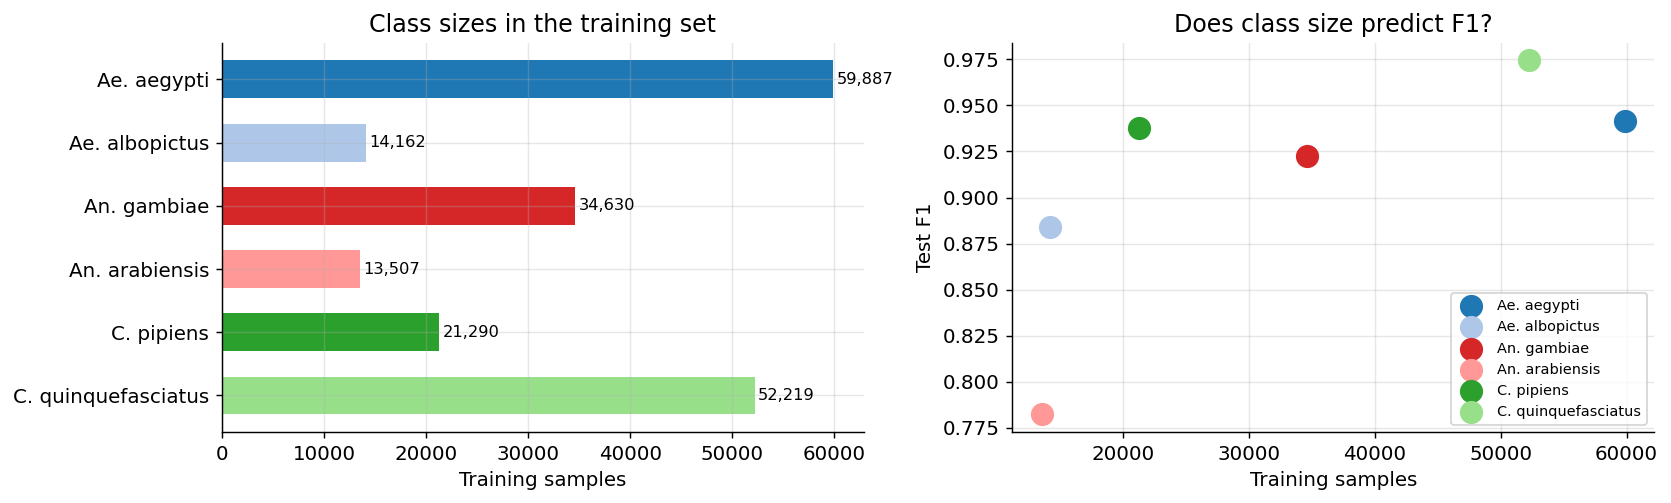

            species  train_n       f1
        Ae. aegypti    59887 0.941492
     Ae. albopictus    14162 0.884091
        An. gambiae    34630 0.922728
     An. arabiensis    13507 0.782250
         C. pipiens    21290 0.937797
C. quinquefasciatus    52219 0.974405


In [35]:
with open(METADATA) as f:
    meta = json.load(f)
with open(METRICS) as f:
    metrics = json.load(f)

train_counts  = meta['class_counts']['train']
f1_per_class  = {sp: v['f1'] for sp, v in metrics['per_class'].items()}
summary = pd.DataFrame({
    'species': SPECIES_ORDER,
    'train_n': [train_counts[s] for s in SPECIES_ORDER],
    'f1':      [f1_per_class[s] for s in SPECIES_ORDER],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
bars = ax.barh(summary['species'], summary['train_n'], color=PALETTE, height=0.6)
ax.set_xlabel('Training samples')
ax.set_title('Class sizes in the training set')
ax.invert_yaxis()
for bar, n in zip(bars, summary['train_n']):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
            f'{n:,}', va='center', fontsize=9)

ax = axes[1]
for sp, color in SPECIES_COLORS.items():
    row = summary[summary['species'] == sp].iloc[0]
    ax.scatter(row['train_n'], row['f1'], s=140, color=color, zorder=3, label=sp)
ax.set_xlabel('Training samples')
ax.set_ylabel('Test F1')
ax.set_title('Does class size predict F1?')
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('fig_class_balance.png', bbox_inches='tight')
plt.show()
print(summary.to_string(index=False))

**Finding:** Class imbalance partially explains the gap, but *Ae. albopictus* has similar training size to *An. arabiensis* yet 10 F1 points higher. Something else drives *An. arabiensis* failure — the spectrograms themselves.

## 3. Confusion matrix – which species are mixed up?

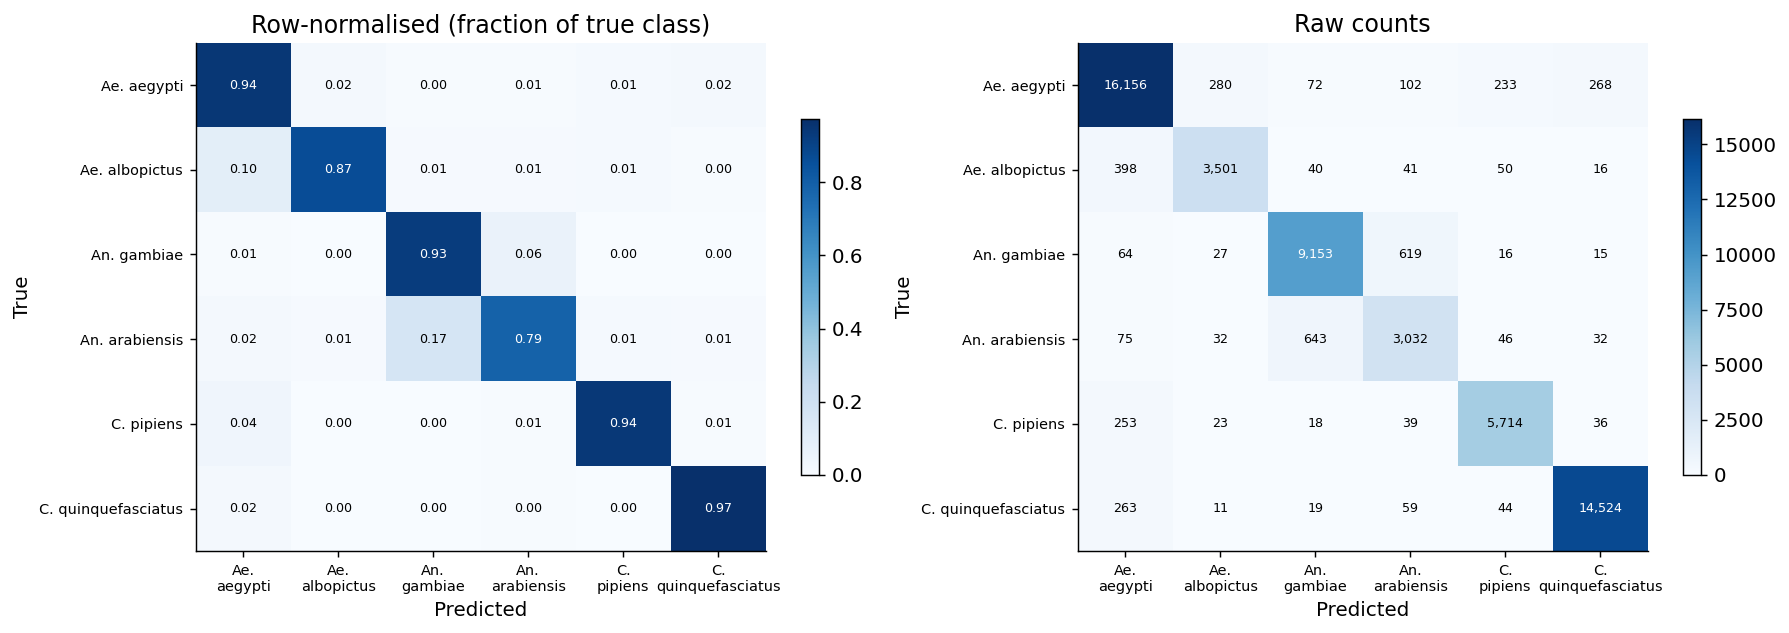

In [36]:
conf_raw  = pd.read_csv(CONFUSION, index_col=0)
conf_raw  = conf_raw.loc[SPECIES_ORDER, SPECIES_ORDER]
conf_norm = conf_raw.div(conf_raw.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt in [
    (axes[0], conf_norm, 'Row-normalised (fraction of true class)', '.2f'),
    (axes[1], conf_raw,  'Raw counts',                              'd'),
]:
    im = ax.imshow(data.values, cmap='Blues', vmin=0, aspect='auto')
    ax.set_xticks(range(len(SPECIES_ORDER)))
    ax.set_yticks(range(len(SPECIES_ORDER)))
    short = [s.replace('. ', '.\n') for s in SPECIES_ORDER]
    ax.set_xticklabels(short, fontsize=8)
    ax.set_yticklabels(SPECIES_ORDER, fontsize=8)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(SPECIES_ORDER)):
        for j in range(len(SPECIES_ORDER)):
            v = data.values[i, j]
            text = f'{v:{fmt}}' if fmt == '.2f' else f'{int(v):,}'
            ax.text(j, i, text, ha='center', va='center', fontsize=7,
                    color='white' if v > data.values.max() * 0.5 else 'black')
    plt.colorbar(im, ax=ax, shrink=0.7)

plt.tight_layout()
plt.savefig('fig_confusion.png', bbox_inches='tight')
plt.show()

**Key finding:** *An. gambiae* ↔ *An. arabiensis* confusion is the dominant error. It is **asymmetric**: 16.7% of *An. arabiensis* samples are labelled as *An. gambiae*, but only 6.3% in the other direction. These are biologically closely related sibling species with nearly identical wingbeat morphology.

## 4. Confidence – is the model overconfident on its errors?

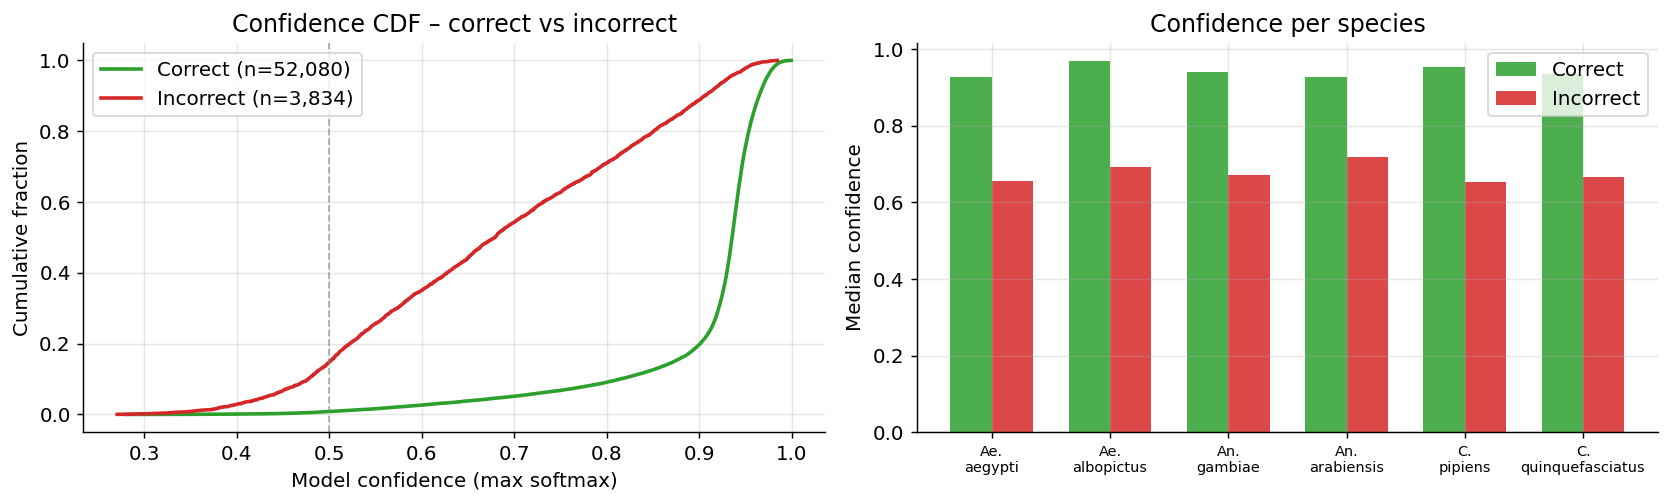

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for label, color, subset in [
    ('Correct',   '#2ca02c', df[df['correct']]),
    ('Incorrect', '#d62728', df[~df['correct']]),
]:
    vals = np.sort(subset['confidence'].values)
    cdf  = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, cdf, color=color, lw=2, label=f'{label} (n={len(vals):,})')
ax.set_xlabel('Model confidence (max softmax)')
ax.set_ylabel('Cumulative fraction')
ax.set_title('Confidence CDF – correct vs incorrect')
ax.axvline(0.5, color='gray', lw=1, ls='--', alpha=0.6)
ax.legend()

ax = axes[1]
stats = df.groupby(['true_species', 'correct'])['confidence'].median().unstack()
stats = stats.reindex(SPECIES_ORDER)
x = np.arange(len(SPECIES_ORDER))
w = 0.35
ax.bar(x - w/2, stats[True],  width=w, color='#2ca02c', alpha=0.85, label='Correct')
ax.bar(x + w/2, stats[False], width=w, color='#d62728', alpha=0.85, label='Incorrect')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('. ', '.\n') for s in SPECIES_ORDER], fontsize=8)
ax.set_ylabel('Median confidence')
ax.set_title('Confidence per species')
ax.legend()

plt.tight_layout()
plt.savefig('fig_confidence.png', bbox_inches='tight')
plt.show()

**Finding:** The model is overconfident on wrong predictions. Median confidence for incorrect *An. gambiae* predictions is around 0.6–0.7 — meaning it is convinced it is right even when it is not. This is dangerous in a deployment context (e.g., disease-vector monitoring) because a high-confidence error looks identical to a high-confidence correct prediction.

## 5. Wingbeat frequency distributions

`f0_hz` is the strongest FFT bin **restricted to 200–1500 Hz** (recomputed from audio; see `results/f0_band_peak.csv`).

The original `spectral_peak_hz` was a global argmax and is often ~6 Hz junk for Anopheles — do not use it for frequency analyses.

If two species have overlapping `f0_hz` distributions, their spectrograms look alike in the wingbeat band.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
axes_flat = axes.flatten()
bins = np.linspace(200, 1500, 80)

for ax, sp in zip(axes_flat, SPECIES_ORDER):
    subset    = df[df['true_species'] == sp]
    correct   = subset[subset['correct']]['f0_hz']
    incorrect = subset[~subset['correct']]['f0_hz']

    ax.hist(correct,   bins=bins, density=True, color=SPECIES_COLORS[sp], alpha=0.7, label='Correct')
    ax.hist(incorrect, bins=bins, density=True, color='#d62728',           alpha=0.5,
            label='Incorrect', histtype='stepfilled')
    ax.axvline(subset['f0_hz'].median(), color='black', ls='--', lw=1, alpha=0.7)
    ax.set_title(sp, fontsize=10)
    ax.set_xlabel('f0_hz (band peak)')
    ax.set_ylabel('Density')

axes_flat[0].legend(fontsize=8)
plt.suptitle('Wingbeat-band peak (200–1500 Hz): correct vs incorrect',
             y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig('fig_freq_by_species.png', bbox_inches='tight')
plt.show()


## 6. The Anopheles confusion – deep dive

We separate predictions into four outcomes and ask: at which frequencies does confusion peak?

In [ ]:
anoph = df[df['true_genus'] == 'Anopheles'].copy()

def outcome_label(row):
    if row['correct']:
        return f"Correct {row['true_species']}"
    elif row['predicted_genus'] == 'Anopheles':
        return 'Confused within Anopheles'
    return 'Confused with other genus'

anoph['outcome'] = anoph.apply(outcome_label, axis=1)
print(anoph['outcome'].value_counts().to_string())
print('\nMedian f0_hz by outcome:')
print(anoph.groupby('outcome')['f0_hz'].median().round(1).to_string())

outcome_colors = {
    'Correct An. gambiae':          '#8b0000',
    'Correct An. arabiensis':       '#ff9896',
    'Confused within Anopheles':    '#ff7f0e',
    'Confused with other genus':    '#9467bd',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
bins2 = np.linspace(200, 1500, 70)
for outcome, grp in anoph.groupby('outcome'):
    ax.hist(grp['f0_hz'], bins=bins2, density=True, alpha=0.5,
            label=f'{outcome} (n={len(grp):,})',
            color=outcome_colors.get(outcome, 'gray'))
ax.set_xlabel('f0_hz (band peak)')
ax.set_ylabel('Density')
ax.set_title('Anopheles: frequency by outcome (full test set)')
ax.legend(fontsize=8)

ax = axes[1]
sample = anoph.sample(min(len(anoph), 4000), random_state=42)
for outcome, grp in sample.groupby('outcome'):
    ax.scatter(grp['f0_hz'], grp['confidence'],
               s=8, alpha=0.25, color=outcome_colors.get(outcome, 'gray'), label=outcome)
ax.set_xlabel('f0_hz (band peak)')
ax.set_ylabel('Model confidence')
ax.set_title('Confidence vs f0 for Anopheles')
ax.legend(fontsize=8, markerscale=3)

plt.tight_layout()
plt.savefig('fig_anopheles_deep_dive.png', bbox_inches='tight')
plt.show()


## 7. Per-frequency accuracy in the overlap zone

In [ ]:
anoph2 = df[df['true_genus'] == 'Anopheles'].copy()
# Full Anopheles – f0_hz already restricted to 200–1500 Hz at extraction time
freq_bins = np.arange(200, 1501, 50)
anoph2['freq_bin'] = pd.cut(anoph2['f0_hz'], bins=freq_bins,
                             labels=freq_bins[:-1] + 25).astype(float)

pivot       = anoph2.groupby(['freq_bin', 'true_species'])['correct'].mean().unstack()
count_pivot = anoph2.groupby(['freq_bin', 'true_species']).size().unstack().fillna(0)

# Hide accuracy points with too few samples
MIN_N = 30

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax = axes[0]
for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    if sp not in pivot.columns:
        continue
    y = pivot[sp].copy()
    y[count_pivot[sp] < MIN_N] = np.nan
    ax.plot(y.index, y, marker='o', color=color, lw=2, ms=5, label=sp)
ax.axhline(0.9, color='gray', ls='--', lw=1, alpha=0.5)
ax.set_ylabel('Accuracy')
ax.set_title(f'Per-bin accuracy – Anopheles (bins with n<{MIN_N} hidden)')
ax.legend()
ax.set_ylim(0, 1.05)

ax = axes[1]
bar_w = 20
for i, (sp, color) in enumerate([('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]):
    if sp in count_pivot.columns:
        ax.bar(count_pivot.index + (i - 0.5)*bar_w, count_pivot[sp],
               width=bar_w, color=color, alpha=0.7, label=sp)
ax.set_xlabel('f0_hz (Hz, bin centre)')
ax.set_ylabel('Sample count')
ax.set_title('Samples per frequency bin – full Anopheles test set')
ax.legend()

OVERLAP = (550, 900)  # mass overlap of the two Anopheles f0 distributions
for ax in axes:
    ax.axvspan(*OVERLAP, alpha=0.08, color='orange')

axes[0].text(sum(OVERLAP)/2, 0.3, 'Overlap\nzone', ha='center', fontsize=9,
             color='darkorange', style='italic')

plt.tight_layout()
plt.savefig('fig_freq_accuracy.png', bbox_inches='tight')
plt.show()

print('Counts in overlap zone', OVERLAP, ':')
in_ov = anoph2[anoph2['f0_hz'].between(*OVERLAP)]
print(in_ov.groupby('true_species').size().to_string())
print('Accuracy in overlap:')
print(in_ov.groupby('true_species')['correct'].mean().round(3).to_string())


## 7b. H2 – Do errors cluster where a clip's frequency is atypical for its species?

**Hypothesis:** Each species has a characteristic wingbeat frequency. Clips whose `f0_hz` drifts far from their species median are harder to classify.

Uses **all** test clips (`f0_hz` = strongest FFT bin in 200–1500 Hz). No junk-peak filter needed.


In [ ]:
# ── Setup: atypicality on FULL test set via f0_hz ────────────────────────────
h2 = df.copy()

species_median = h2.groupby('true_species')['f0_hz'].median()
h2['sp_median']  = h2['true_species'].map(species_median)
h2['delta_hz']   = h2['f0_hz'] - h2['sp_median']
h2['abs_delta']  = h2['delta_hz'].abs()

print("Per-species median f0_hz (full test set):")
print(species_median.reindex(SPECIES_ORDER).round(1).to_string())
print("\nn per species:")
print(h2.groupby('true_species').size().reindex(SPECIES_ORDER).to_string())

# ── Chart A: error rate vs f0_hz per species ─────────────────────────────────
BIN_W = 50
MIN_N = 30
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)

for ax, sp in zip(axes.flatten(), SPECIES_ORDER):
    sub    = h2[h2['true_species'] == sp].copy()
    lo     = (sub['f0_hz'].min() // BIN_W) * BIN_W
    hi     = (sub['f0_hz'].max() // BIN_W + 1) * BIN_W
    edges  = np.arange(lo, hi + BIN_W, BIN_W)
    labels = edges[:-1] + BIN_W / 2

    sub['bin'] = pd.cut(sub['f0_hz'], bins=edges, labels=labels).astype(float)
    agg = sub.groupby('bin').agg(err_rate=('correct', lambda x: 1 - x.mean()),
                                  n=('correct', 'size')).reset_index()
    agg = agg[agg['n'] >= MIN_N]

    color = SPECIES_COLORS[sp]
    ax.bar(agg['bin'], agg['err_rate'], width=BIN_W * 0.8, color=color, alpha=0.7)
    ax.axvline(species_median[sp], color='black', lw=1.5, ls='--',
               label=f'median {species_median[sp]:.0f} Hz')
    ax.set_title(sp, fontsize=9)
    ax.set_xlabel('f0_hz')
    ax.set_ylabel('Error rate')
    ax.set_ylim(0, 0.55)
    ax.legend(fontsize=7)

plt.suptitle(f'Chart A – Error rate vs f0_hz (full data; bins with n<{MIN_N} hidden)', fontsize=11)
plt.tight_layout()
plt.savefig('fig_h2_error_vs_f0.png', bbox_inches='tight')
plt.show()


In [ ]:
# ── Chart B: error rate vs |delta_hz| (atypicality), one curve per species ───
DELTA_EDGES = [0, 50, 100, 150, 200, 300, 500, 1000]
delta_labels = [f'{DELTA_EDGES[i]}–{DELTA_EDGES[i+1]}' for i in range(len(DELTA_EDGES)-1)]
MIN_N = 30

h2['delta_bin'] = pd.cut(h2['abs_delta'], bins=DELTA_EDGES, labels=delta_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = {lab: i for i, lab in enumerate(delta_labels)}

ax = axes[0]
for sp in SPECIES_ORDER:
    sub = h2[h2['true_species'] == sp]
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('correct', lambda x: 1 - x.mean()),
        n=('correct', 'size')
    )
    agg = agg[agg['n'] >= MIN_N]
    xs = [x_pos[str(i)] for i in agg.index]
    ax.plot(xs, agg['err_rate'], marker='o', ms=5,
            color=SPECIES_COLORS[sp], lw=2, label=f"{sp} (n={len(sub):,})")

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title(f'Chart B – Error rate vs atypicality\n(full data; n≥{MIN_N} per point)')
ax.legend(fontsize=7)

ax = axes[1]
for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    sub = h2[h2['true_species'] == sp]
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('correct', lambda x: 1 - x.mean()),
        n=('correct', 'size')
    )
    agg = agg[agg['n'] >= MIN_N]
    xs = [x_pos[str(i)] for i in agg.index]
    ax.plot(xs, agg['err_rate'], marker='o', ms=6, color=color, lw=2,
            label=f'{sp} (n={len(sub):,})')
    for x, (_, row) in zip(xs, agg.iterrows()):
        ax.annotate(f"n={int(row['n'])}", (x, row['err_rate']),
                    textcoords='offset points', xytext=(0, 6),
                    ha='center', fontsize=7, color=color)

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title('Chart C – Anopheles error vs atypicality (full data)')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig_h2_error_vs_atypicality.png', bbox_inches='tight')
plt.show()

rows = []
for sp in SPECIES_ORDER:
    sub = h2[h2['true_species'] == sp]
    thr = sub['abs_delta'].median()
    typical = sub[sub['abs_delta'] <= thr]
    atypic  = sub[sub['abs_delta'] > thr]
    te = 1 - typical['correct'].mean()
    ae = 1 - atypic['correct'].mean()
    rows.append({
        'species': sp,
        'n': len(sub),
        'median_f0_hz': round(species_median[sp], 1),
        'typical_err': round(te, 3),
        'atypical_err': round(ae, 3),
        'lift': round(ae / max(te, 1e-6), 2),
    })

stats_table = pd.DataFrame(rows)
print('\nH2 stats – typical (bottom 50% |delta|) vs atypical (top 50% |delta|):')
print(stats_table.to_string(index=False))
print('\nlift = atypical_err / typical_err  (>1 supports H2; <1 is opposite)')


**H2 finding (full data, `f0_hz`):**  
With all test clips, H2 is **mixed**, not uniformly supported:
- **Supported:** *Ae. albopictus*, *C. pipiens*, *An. gambiae*, *C. quinquefasciatus* (lift > 1).
- **Not supported / reversed:** *An. arabiensis* and *Ae. aegypti* (atypical clips are *easier* or no worse).

So “far from species median ⇒ harder” is **not** the main Anopheles story for *arabiensis*. Their high baseline error sits near their own centre too. Next: H6 (event duration) or H7 (background / `raw_rms`), or Phase II attention.


## 8. Real spectrogram analysis

We read WAV files directly from `archive.zip` (no extraction needed) and compute log-Mel spectrograms using the **exact same pipeline as the trained model**.

For each species we show correctly classified samples. Then we zoom into the *Anopheles* confusion: placing a confused sample next to a correctly classified one at the same frequency to see what the model could not distinguish.

In [43]:
import zipfile, io
from math import gcd
from pathlib import Path

import numpy as np
import soundfile as sf
from scipy.signal import stft

# ── archive.zip lives next to the repo (workspace root) ────────────────
ZIP_PATH = Path(r'D:\AI and Vis\archive.zip')
print(f"ZIP_PATH: {ZIP_PATH}")
print(f"ZIP_PATH exists: {ZIP_PATH.exists()}")

# ── Audio / spectrogram parameters (must match the trained model exactly) ────
SR, N_FFT, HOP, N_MELS = 8000, 512, 32, 128
F_MIN, F_MAX, TOP_DB    = 0.0, 4000.0, 80.0
N_SAMPLES               = round(SR * 0.65)   # 5200

def hz_to_mel(hz):  return 2595 * np.log10(1 + hz / 700)
def mel_to_hz(mel): return 700 * (10 ** (mel / 2595) - 1)

def _build_mel_fb():
    mel_pts = np.linspace(hz_to_mel(F_MIN), hz_to_mel(F_MAX), N_MELS + 2)
    hz_pts  = mel_to_hz(mel_pts)
    bins    = np.floor((N_FFT + 1) * hz_pts / SR).astype(int)
    fb      = np.zeros((N_MELS, N_FFT // 2 + 1))
    for m in range(1, N_MELS + 1):
        lo, mid, hi = bins[m-1], bins[m], bins[m+1]
        for k in range(lo, mid):
            if mid > lo: fb[m-1, k] = (k - lo) / (mid - lo)
        for k in range(mid, hi):
            if hi  > mid: fb[m-1, k] = (hi - k) / (hi - mid)
    return fb

MEL_FB = _build_mel_fb()

def compute_logmel(signal):
    signal = np.asarray(signal, dtype=np.float32)
    signal = signal - signal.mean()
    _, _, Zxx = stft(signal, fs=SR, nperseg=N_FFT, noverlap=N_FFT - HOP, window='hann')
    mel_s   = MEL_FB @ np.abs(Zxx) ** 2
    log_mel = 10 * np.log10(np.maximum(mel_s, 1e-10))
    return np.maximum(log_mel, log_mel.max() - TOP_DB)

def load_wav_from_zip(zf, relative_path):
    data  = zf.read(relative_path)
    audio, orig_sr = sf.read(io.BytesIO(data), dtype='float32', always_2d=True)
    mono = audio.mean(axis=1)
    if orig_sr != SR:
        from scipy.signal import resample_poly
        d = gcd(orig_sr, SR)
        mono = resample_poly(mono, SR // d, orig_sr // d).astype(np.float32)
    n = N_SAMPLES
    if len(mono) > n:
        start = (len(mono) - n) // 2
        mono  = mono[start:start + n]
    elif len(mono) < n:
        left = (n - len(mono)) // 2
        mono = np.pad(mono, (left, n - len(mono) - left))
    return mono.astype(np.float32)

print(f"Mel filterbank shape: {MEL_FB.shape}")

ZIP_PATH: D:\AI and Vis\archive.zip
ZIP_PATH exists: True
Mel filterbank shape: (128, 257)


In [ ]:
# ── 8a. One representative correct spectrogram per species ───────────────────
N_PER_SPECIES = 1   # increase if you want more examples

sample_rows = (
    df[df['correct']]
    .groupby('true_species', group_keys=False)
    .apply(lambda g: g.sample(N_PER_SPECIES, random_state=42))
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for ax, (_, row) in zip(axes, sample_rows.iterrows()):
        sig  = load_wav_from_zip(zf, row['relative_path'])
        spec = compute_logmel(sig)
        ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                  extent=[0, 650, F_MIN, F_MAX])
        ax.set_title(f"{row['true_species']}\n{row['f0_hz']:.0f} Hz",
                     fontsize=8, color=SPECIES_COLORS[row['true_species']])
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Freq (Hz)')
        ax.grid(False)

plt.suptitle('Correctly classified – one real spectrogram per species', fontsize=11)
plt.tight_layout()
plt.savefig('fig_real_spectrograms_correct.png', bbox_inches='tight')
plt.show()

# ── 8b. Anopheles confusion: correct vs confused side-by-side ────────────────
# Pick samples in the overlap zone (400–650 Hz) for maximum visual impact
overlap_mask = df['f0_hz'].between(550, 900)  # Anopheles f0 mass overlap

anoph_correct_gam = df[df['true_species'].eq('An. gambiae')   & df['correct'] & overlap_mask]
anoph_correct_ara = df[df['true_species'].eq('An. arabiensis') & df['correct'] & overlap_mask]
anoph_wrong_ara   = df[df['true_species'].eq('An. arabiensis') & ~df['correct']
                       & df['predicted_species'].eq('An. gambiae') & overlap_mask]
anoph_wrong_gam   = df[df['true_species'].eq('An. gambiae')   & ~df['correct']
                       & df['predicted_species'].eq('An. arabiensis') & overlap_mask]

picks = [
    (anoph_correct_gam, 'An. gambiae\n✓ correct',         '#8b0000'),
    (anoph_wrong_gam,   'An. gambiae\n✗ predicted arabiensis', '#ff7f0e'),
    (anoph_correct_ara, 'An. arabiensis\n✓ correct',       '#ff9896'),
    (anoph_wrong_ara,   'An. arabiensis\n✗ predicted gambiae',  '#ff7f0e'),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for col, (pool, label, color) in enumerate(picks):
        for row_idx in range(2):
            ax   = axes[row_idx][col]
            row  = pool.sample(1, random_state=row_idx * 7 + col).iloc[0]
            sig  = load_wav_from_zip(zf, row['relative_path'])
            spec = compute_logmel(sig)
            ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                      extent=[0, 650, F_MIN, F_MAX])
            if row_idx == 0:
                ax.set_title(f'{label}\nconf={row["confidence"]:.2f}  peak={row["f0_hz"]:.0f} Hz',
                             fontsize=8, color=color)
            else:
                ax.set_title(f'conf={row["confidence"]:.2f}  peak={row["f0_hz"]:.0f} Hz',
                             fontsize=8)
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Freq (Hz)')
            ax.grid(False)
            border_color = '#d62728' if '✗' in label else '#2ca02c'
            for spine in ax.spines.values():
                spine.set_edgecolor(border_color)
                spine.set_linewidth(2)

plt.suptitle('Anopheles in the overlap zone (550–900 Hz): correct (green border) vs confused (red border)',
             fontsize=11)
plt.tight_layout()
plt.savefig('fig_anopheles_spectrograms.png', bbox_inches='tight')
plt.show()


## 8b. Listen – can you hear the difference?

Play the samples below. If you cannot reliably tell *An. gambiae* from *An. arabiensis* by ear, the model's confusion is acoustically justified.

In [ ]:
from IPython.display import Audio, display

overlap_mask = df['f0_hz'].between(550, 900)

listen_cases = {
    'An. gambiae   – CORRECT (overlap zone)':       df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae   – WRONG → predicted arabiensis': df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis – CORRECT (overlap zone)':      df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis – WRONG → predicted gambiae':   df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in listen_cases.items():
        row = pool.sample(1, random_state=99).iloc[0]
        sig = load_wav_from_zip(zf, row['relative_path'])
        print(f"\n{label}")
        print(f"  peak={row['f0_hz']:.0f} Hz  conf={row['confidence']:.2f}")
        display(Audio(sig, rate=SR))


## 8c. Average spectrograms & difference maps

Individual samples are noisy. Averaging over hundreds of samples cancels the noise and reveals any **systematic** difference in energy distribution between correct and confused predictions.

In [ ]:
overlap_mask = df['f0_hz'].between(550, 900)

N_AVG = 50   # start small; raise to 300 for final run

categories = {
    'An. gambiae correct':    df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae confused':   df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis correct': df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis confused':df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

print("Computing average spectrograms...")
avg_specs = {}
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in categories.items():
        rows  = pool.sample(min(N_AVG, len(pool)), random_state=0)
        stack = []
        for _, row in rows.iterrows():
            try:
                sig = load_wav_from_zip(zf, row['relative_path'])
                stack.append(compute_logmel(sig))
            except Exception:
                pass
        avg_specs[label] = np.mean(stack, axis=0)
        print(f"  {label}: {len(stack)} samples")

# ── 4 average spectrograms ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
vmin = min(s.min() for s in avg_specs.values())
vmax = max(s.max() for s in avg_specs.values())

for col, label in enumerate(categories):
    ax = axes[0][col]
    ax.imshow(avg_specs[label], origin='lower', aspect='auto', cmap='magma',
              vmin=vmin, vmax=vmax, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'Mean: {label}', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)

# ── 2 difference maps (confused − correct) ──────────────────────────────────
for col, (sp, c_lbl, w_lbl) in enumerate([
    ('An. gambiae',    'An. gambiae correct',    'An. gambiae confused'),
    ('An. arabiensis', 'An. arabiensis correct', 'An. arabiensis confused'),
]):
    ax   = axes[1][col]
    diff = avg_specs[w_lbl] - avg_specs[c_lbl]
    lim  = np.percentile(np.abs(diff), 98)
    im   = ax.imshow(diff, origin='lower', aspect='auto', cmap='RdBu_r',
                     vmin=-lim, vmax=lim, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'{sp}
confused − correct  (red = more energy when confused)', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=0.8, label='ΔdB')

# ── frequency profiles ───────────────────────────────────────────────────────
ax = axes[1][2]
styles = [('#8b0000','-'), ('#ff7f0e','--'), ('#ff9896','-'), ('#d62728',':')]
for (label, _), (color, ls) in zip(categories.items(), styles):
    ax.plot(avg_specs[label].mean(axis=1), label=label, color=color, ls=ls, lw=1.5)
ax.set_xlabel('Mel bin'); ax.set_ylabel('Mean energy (dB)')
ax.set_title('Frequency profile'); ax.legend(fontsize=7)

axes[1][3].axis('off')   # spare panel

plt.tight_layout()
plt.savefig('fig_avg_spectrograms.png', bbox_inches='tight')
plt.show()


## 9. Training curve

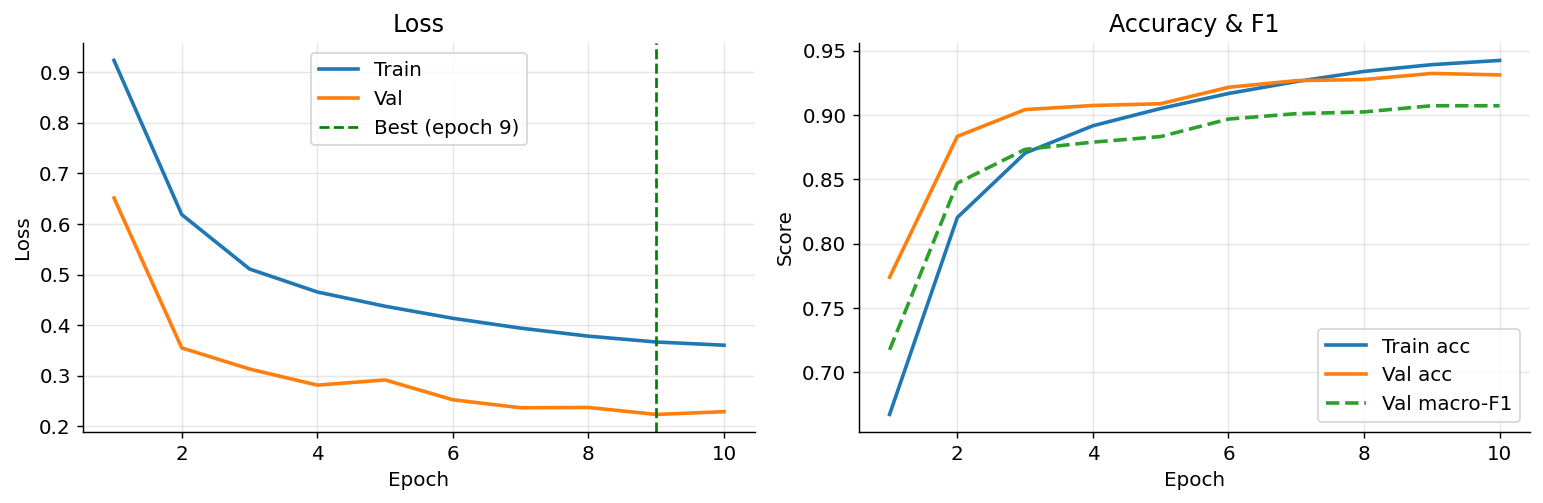

In [47]:
hist = pd.read_csv(HISTORY)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
best_epoch = hist.loc[hist['validation_macro_f1'].idxmax(), 'epoch']

ax = axes[0]
ax.plot(hist['epoch'], hist['train_loss'],      lw=2, color='#1f77b4', label='Train')
ax.plot(hist['epoch'], hist['validation_loss'], lw=2, color='#ff7f0e', label='Val')
ax.axvline(best_epoch, color='green', ls='--', lw=1.5, label=f'Best (epoch {best_epoch})')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Loss'); ax.legend()

ax = axes[1]
ax.plot(hist['epoch'], hist['train_accuracy'],      lw=2, color='#1f77b4', label='Train acc')
ax.plot(hist['epoch'], hist['validation_accuracy'], lw=2, color='#ff7f0e', label='Val acc')
ax.plot(hist['epoch'], hist['validation_macro_f1'], lw=2, color='#2ca02c', ls='--', label='Val macro-F1')
ax.set_xlabel('Epoch'); ax.set_ylabel('Score')
ax.set_title('Accuracy & F1'); ax.legend()

plt.tight_layout()
plt.savefig('fig_training_curve.png', bbox_inches='tight')
plt.show()

## 10. Summary of findings

| Finding | Evidence | Implication |
|---|---|---|
| *An. arabiensis* has the lowest F1 (0.782) | Per-class metrics | Further investigation needed |
| *An. gambiae* ↔ *An. arabiensis* confusion dominates errors | Confusion matrix | Species boundary is acoustically weak |
| Confusion is **asymmetric**: 16.7% of *An. arabiensis* → *An. gambiae*, only 6.3% reverse | Confusion matrix | *An. arabiensis* harder to separate |
| Errors are **high-confidence** (model is overconfident) | Confidence CDF | Dangerous in deployment – wrong with certainty |
| Original `spectral_peak_hz` is unreliable (~6 Hz for most Anopheles) | Compare to `f0_hz` | Frequency analyses must use band-limited `f0_hz` |
| With `f0_hz` on **all** clips, Anopheles peaks still overlap (~550–900 Hz) | Frequency histograms | Sibling species remain hard to separate by peak alone |
| H2 (atypical f0 → error) is **mixed** on full data | H2 lift table | Strong for albopictus; weak/reversed for arabiensis |

### Open questions for Phase II
- Does CBAM attention focus on the **same harmonic lines** for both Anopheles in the overlap zone?
- Are confused samples' internal feature representations actually the same cluster in the penultimate layer?
- Could training with a **paired contrastive loss** on these two species improve separation?
- H6 (partial events) / H7 (background) given H2 is not the main arabiensis driver?


## 11. Deeper analysis – what drives the Anopheles confusion?

The asymmetry (16.7% arabiensis→gambiae vs 6.3% gambiae→arabiensis) and the overconfidence on wrong predictions demand a deeper look. Four complementary angles:

| # | Question | Method |
|---|---|---|
| 11a | Do confused samples form a sub-cluster in probability space? | PCA on 6 prob columns |
| 11b | Are errors concentrated in specific recording sessions? | Per-session error rates |
| 11c | Is the model making *close calls* or *confident mistakes*? | prob_gambiae vs prob_arabiensis scatter |
| 11d | Is the error distribution uniform across sessions (Gini / Lorenz)? | Session uniformity analysis |

### 11a. Sub-clusters in probability space (PCA on the 6 probability outputs)

In [ ]:
an = df[df['true_species'].isin(['An. gambiae', 'An. arabiensis'])].copy()
prob_cols = ['prob_aegypti', 'prob_albopictus', 'prob_gambiae', 'prob_arabiensis', 'prob_pipiens', 'prob_quinquefasciatus']
X = an[prob_cols].to_numpy(dtype=float)
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
scores = Xc @ Vt[:2].T
loadings = Vt[:2]
var_ratio = S**2 / np.sum(S**2)
an['pc1'], an['pc2'] = scores[:, 0], scores[:, 1]
an['correct'] = an['correct'].astype(bool)

to_ga = (an['true_species'] == 'An. gambiae') & (an['predicted_species'] == 'An. arabiensis')
to_ar = (an['true_species'] == 'An. arabiensis') & (an['predicted_species'] == 'An. gambiae')
confused = an[to_ga | to_ar]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax1, ax2, ax3, ax4 = axes.ravel()

for sp, c in [('An. gambiae', 'red'), ('An. arabiensis', 'pink')]:
    m = an['true_species'] == sp
    ax1.scatter(an.loc[m, 'pc1'], an.loc[m, 'pc2'], s=12, alpha=0.6, c=c, label=sp)
ax1.set_title('True species in PC space')
ax1.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax1.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax1.legend()

for flag, c, lab in [(True, 'green', 'correct'), (False, 'red', 'wrong')]:
    m = an['correct'] == flag
    ax2.scatter(an.loc[m, 'pc1'], an.loc[m, 'pc2'], s=12, alpha=0.6, c=c, label=lab)
ax2.set_title('Correct vs incorrect predictions in PC space')
ax2.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax2.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax2.legend()

for m, c, lab in [(to_ga[to_ga | to_ar], 'darkorange', 'gambiae -> arabiensis'),
                  (to_ar[to_ga | to_ar], 'purple', 'arabiensis -> gambiae')]:
    ax3.scatter(confused.loc[m, 'pc1'], confused.loc[m, 'pc2'], s=14, alpha=0.7, c=c, label=lab)
ax3.set_title(f'Confused samples only (n={len(confused)})')
ax3.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax3.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax3.legend()

x = np.arange(len(prob_cols))
w = 0.38
short = [c.replace('prob_', '') for c in prob_cols]
ax4.bar(x - w / 2, loadings[0], w, label=f'PC1 ({var_ratio[0]:.1%} var)')
ax4.bar(x + w / 2, loadings[1], w, label=f'PC2 ({var_ratio[1]:.1%} var)')
ax4.axhline(0, color='black', lw=0.8)
ax4.set_xticks(x)
ax4.set_xticklabels(short, rotation=30, ha='right')
ax4.set_title('PCA loadings on the 6 probability dimensions')
ax4.legend()

plt.tight_layout()
plt.savefig('fig_subcluster_probspace.png', dpi=150, bbox_inches='tight')
plt.show()

n_conf = len(confused)
n_ga, n_ar = int(to_ga.sum()), int(to_ar.sum())
print(f"Anopheles test samples: {len(an)}")
print(f"Confused: {n_conf} ({n_conf / len(an):.1%}) - gambiae->arabiensis: {n_ga}, arabiensis->gambiae: {n_ar}")

P = an[['pc1', 'pc2']].to_numpy()
conf_mask = (to_ga | to_ar).to_numpy()
ok_mask = (an['correct']).to_numpy()
c_conf = P[conf_mask].mean(axis=0)
c_ok = P[ok_mask].mean(axis=0)
d_conf = np.linalg.norm(P[conf_mask] - c_conf, axis=1)
d_ok = np.linalg.norm(P[conf_mask] - c_ok, axis=1)
frac_closer = np.mean(d_conf < d_ok)
print(f"Centroid distance (confused vs correct, PC space): {np.linalg.norm(c_conf - c_ok):.3f}")
print(f"Confused samples closer to the confused centroid than the correct centroid: {frac_closer:.1%}")
if frac_closer > 0.8:
    print("Verdict: confused samples form a distinct sub-cluster")
elif frac_closer < 0.6:
    print("Verdict: confused samples are mixed with correct samples")
else:
    print("Verdict: confused samples partially separate from correct samples")

### 11b. Session-level error clustering – is confusion driven by specific recording sessions?

In [ ]:
MIN_N, TOP_N = 10, 20
ARAB, GAMB = 'An. arabiensis', 'An. gambiae'

def session_table(sp):
    d = df[df['true_species'] == sp]
    t = d.groupby('session')['correct'].agg(n='size', n_correct='sum')
    t['errors'] = t['n'] - t['n_correct']
    t['error_rate'] = t['errors'] / t['n']
    return t, 1 - d['correct'].astype(bool).mean()

arab_all, arab_mean = session_table(ARAB)
gamb_all, gamb_mean = session_table(GAMB)
arab = arab_all[arab_all['n'] >= MIN_N]
gamb = gamb_all[gamb_all['n'] >= MIN_N]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, t, sp, mean in [(axes[0], arab, ARAB, arab_mean), (axes[1], gamb, GAMB, gamb_mean)]:
    top = t.nlargest(TOP_N, 'error_rate').iloc[::-1]
    ax.barh(top.index.astype(str), top['error_rate'], color=SPECIES_COLORS[sp])
    ax.axvline(mean, color='k', ls='--', lw=1, label=f'species mean {mean:.2f}')
    ax.set(title=f'{sp}: top {TOP_N} sessions (n >= {MIN_N})', xlabel='error rate')
    ax.legend(loc='lower right')

both = arab.join(gamb, lsuffix='_arab', rsuffix='_gamb', how='inner')
rho = both['error_rate_gamb'].corr(both['error_rate_arab'], method='spearman')
ax = axes[2]
sc = ax.scatter(both['error_rate_gamb'], both['error_rate_arab'], c=both['n_arab'], cmap='viridis', s=40)
ax.plot([0, 1], [0, 1], ls=':', c='grey')
plt.colorbar(sc, ax=ax, label='An. arabiensis samples in session')
ax.set(title=f'Shared sessions (n={len(both)}), Spearman rho={rho:.2f}',
       xlabel='An. gambiae session error rate', ylabel='An. arabiensis session error rate')

plt.tight_layout()
plt.savefig('fig_session_errors.png', dpi=150, bbox_inches='tight')
plt.show()

def top_decile_share(sp):
    t, _ = session_table(sp)
    k = max(1, int(np.ceil(0.10 * len(t))))
    e = t['errors'].sort_values(ascending=False)
    return k, len(t), e.iloc[:k].sum() / e.sum()

for sp in [ARAB, GAMB]:
    k, n_sess, share = top_decile_share(sp)
    print(f'{sp}: top 10% of sessions ({k} of {n_sess}) hold {share:.1%} of all errors')

### 11c. Probability scatter – close calls or confident mistakes?

In [ ]:
an = df[df['true_species'].str.startswith('An.')].copy()
an['correct'] = an['correct'].astype(bool)
an['margin'] = (an['prob_gambiae'] - an['prob_arabiensis']).abs()
samp = an.sample(n=min(5000, len(an)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

ax = axes[0]
for sp, g in samp.groupby('true_species'):
    ax.scatter(g['prob_gambiae'], g['prob_arabiensis'], s=6, alpha=0.3,
               color=SPECIES_COLORS.get(sp, 'gray'), label=sp)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='P(An. gambiae)', ylabel='P(An. arabiensis)',
       title='Probability split by true species')
ax.legend(markerscale=3)

ax = axes[1]
for ok, color, label in [(True, 'green', 'correct'), (False, 'red', 'incorrect')]:
    g = samp[samp['correct'] == ok]
    ax.scatter(g['prob_gambiae'], g['prob_arabiensis'], s=6, alpha=0.3, color=color, label=label)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='P(An. gambiae)', ylabel='P(An. arabiensis)',
       title='Correct vs incorrect predictions')
ax.legend(markerscale=3)

ax = axes[2]
bins = np.linspace(0, 1, 41)
ax.hist(an.loc[an['correct'], 'margin'], bins=bins, alpha=0.5, density=True, color='green', label='correct')
ax.hist(an.loc[~an['correct'], 'margin'], bins=bins, alpha=0.5, density=True, color='red', label='incorrect')
ax.set(xlabel='|P(gambiae) - P(arabiensis)|', ylabel='Density', title='Decision margin')
ax.legend()

plt.tight_layout()
plt.savefig('fig_prob_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

correct_m = an.loc[an['correct'], 'margin']
wrong_m = an.loc[~an['correct'], 'margin']
print(f"Median decision margin - correct: {correct_m.median():.3f}, incorrect: {wrong_m.median():.3f}")
print(f"Errors with margin > 0.3 (confidently wrong): {(wrong_m > 0.3).mean():.1%} of {len(wrong_m)} errors")

### 11d. Session uniformity – are errors spread evenly or concentrated in a few sessions?

In [ ]:
SP = ['An. gambiae', 'An. arabiensis']
anop = df[df['true_species'].isin(SP)].copy()
anop['err'] = ~anop['correct'].astype(bool)

g_all = (anop.groupby(['session', 'true_species'])
             .agg(n=('err', 'size'), errors=('err', 'sum'))
             .reset_index())
g_all['err_rate'] = g_all['errors'] / g_all['n']

arab_sessions = g_all.loc[g_all['true_species'] == 'An. arabiensis', 'session'].unique()
rate = (g_all[g_all['session'].isin(arab_sessions)]
        .pivot(index='session', columns='true_species', values='err_rate')
        .reindex(columns=SP))
both = rate.dropna()
print(f'Arabiensis sessions: {len(rate)} | sessions with both species: {len(both)}')
print(both.median().rename('median session error rate'))

def gini(counts):
    x = np.sort(np.asarray(counts, dtype=float))
    n = len(x)
    i = np.arange(1, n + 1)
    return 2 * np.sum(i * x) / (n * np.sum(x)) - (n + 1) / n

lorenz, ginis, rho = {}, {}, {}
for sp in SP:
    sub = g_all[g_all['true_species'] == sp]
    e = np.sort(sub['errors'].to_numpy(dtype=float))
    cs = np.concatenate([[0], np.cumsum(e) / e.sum()])
    lorenz[sp] = (np.arange(len(cs)) / len(e), cs)
    ginis[sp] = gini(e)
    rho[sp] = sub['n'].corr(sub['err_rate'], method='spearman')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
parts = ax.violinplot([both[sp] for sp in SP], showmedians=True)
for body, sp in zip(parts['bodies'], SP):
    body.set_facecolor(SPECIES_COLORS[sp])
    body.set_alpha(0.8)
ax.set_xticks([1, 2])
ax.set_xticklabels(SP)
ax.set_ylabel('Session error rate')
ax.set_title('Session-level error rate (sessions with both)')

ax = axes[1]
for sp in SP:
    x, y = lorenz[sp]
    ax.plot(x, y, color=SPECIES_COLORS[sp], label=f'{sp} (Gini={ginis[sp]:.2f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='uniform')
ax.set(xlabel='Cumulative fraction of sessions', ylabel='Cumulative fraction of errors',
       title='Error concentration across sessions')
ax.legend()

ax = axes[2]
for sp in SP:
    sub = g_all[g_all['true_species'] == sp]
    ax.scatter(sub['n'], sub['err_rate'], s=18, alpha=0.7, color=SPECIES_COLORS[sp],
               label=f'{sp} (rho={rho[sp]:.2f})')
ax.set(xlabel='Session sample count', ylabel='Session error rate', title='Session size vs error rate')
ax.legend()

fig.tight_layout()
fig.savefig('fig_session_uniformity.png', dpi=150, bbox_inches='tight')
plt.show()

for sp in SP:
    print(f'{sp}: sessions={len(g_all[g_all["true_species"] == sp])}, Gini={ginis[sp]:.3f}, Spearman(size, error rate)={rho[sp]:.3f}')